# Lab 9&10: PCA Analysis
## With Hypoxia Data

------
Name = "Noah Runions"

Before you turn this assignment in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel Restart) and then **run all cells** (in the menubar, select Cell and Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only




***Figures:*** For any figures, label axis and title clearly for full points. 



Lab TA: Lee Ochs

## Lab Objectives:

1. Data visualization 
2. Prepare data for PCA 
3. Interpret PCA results
4. Perform some ANOVA analysis for the PCA results

## Lab Activities: 
This lab has two parts, A (30 points), B (30 points),and bonus questions (5 points). Be sure to follow the instructions and complete each parts. 


Part A (30 points): Data visulization and preparation

In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from statsmodels.stats.multicomp import pairwise_tukeyhsd

### Part A (30 points): Data Exploration, Visualization, and create PCA model

In [2]:
#read your data in

#windows
#lab10_observation = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab10\Lab10_observations_gulf_final.csv')

#linux
lab10_observation = pd.read_csv(r'/home/noahr/pythonProjects/OCNG470/Lab10/Lab10_observations_gulf_final.csv')

- plot pairwise relationships to see if you can spot any patterns 
- plot varaibles oxy, sal, nit, sil, seat, pho, sdep, and bdep
- color them based on one or two variables you think may be important

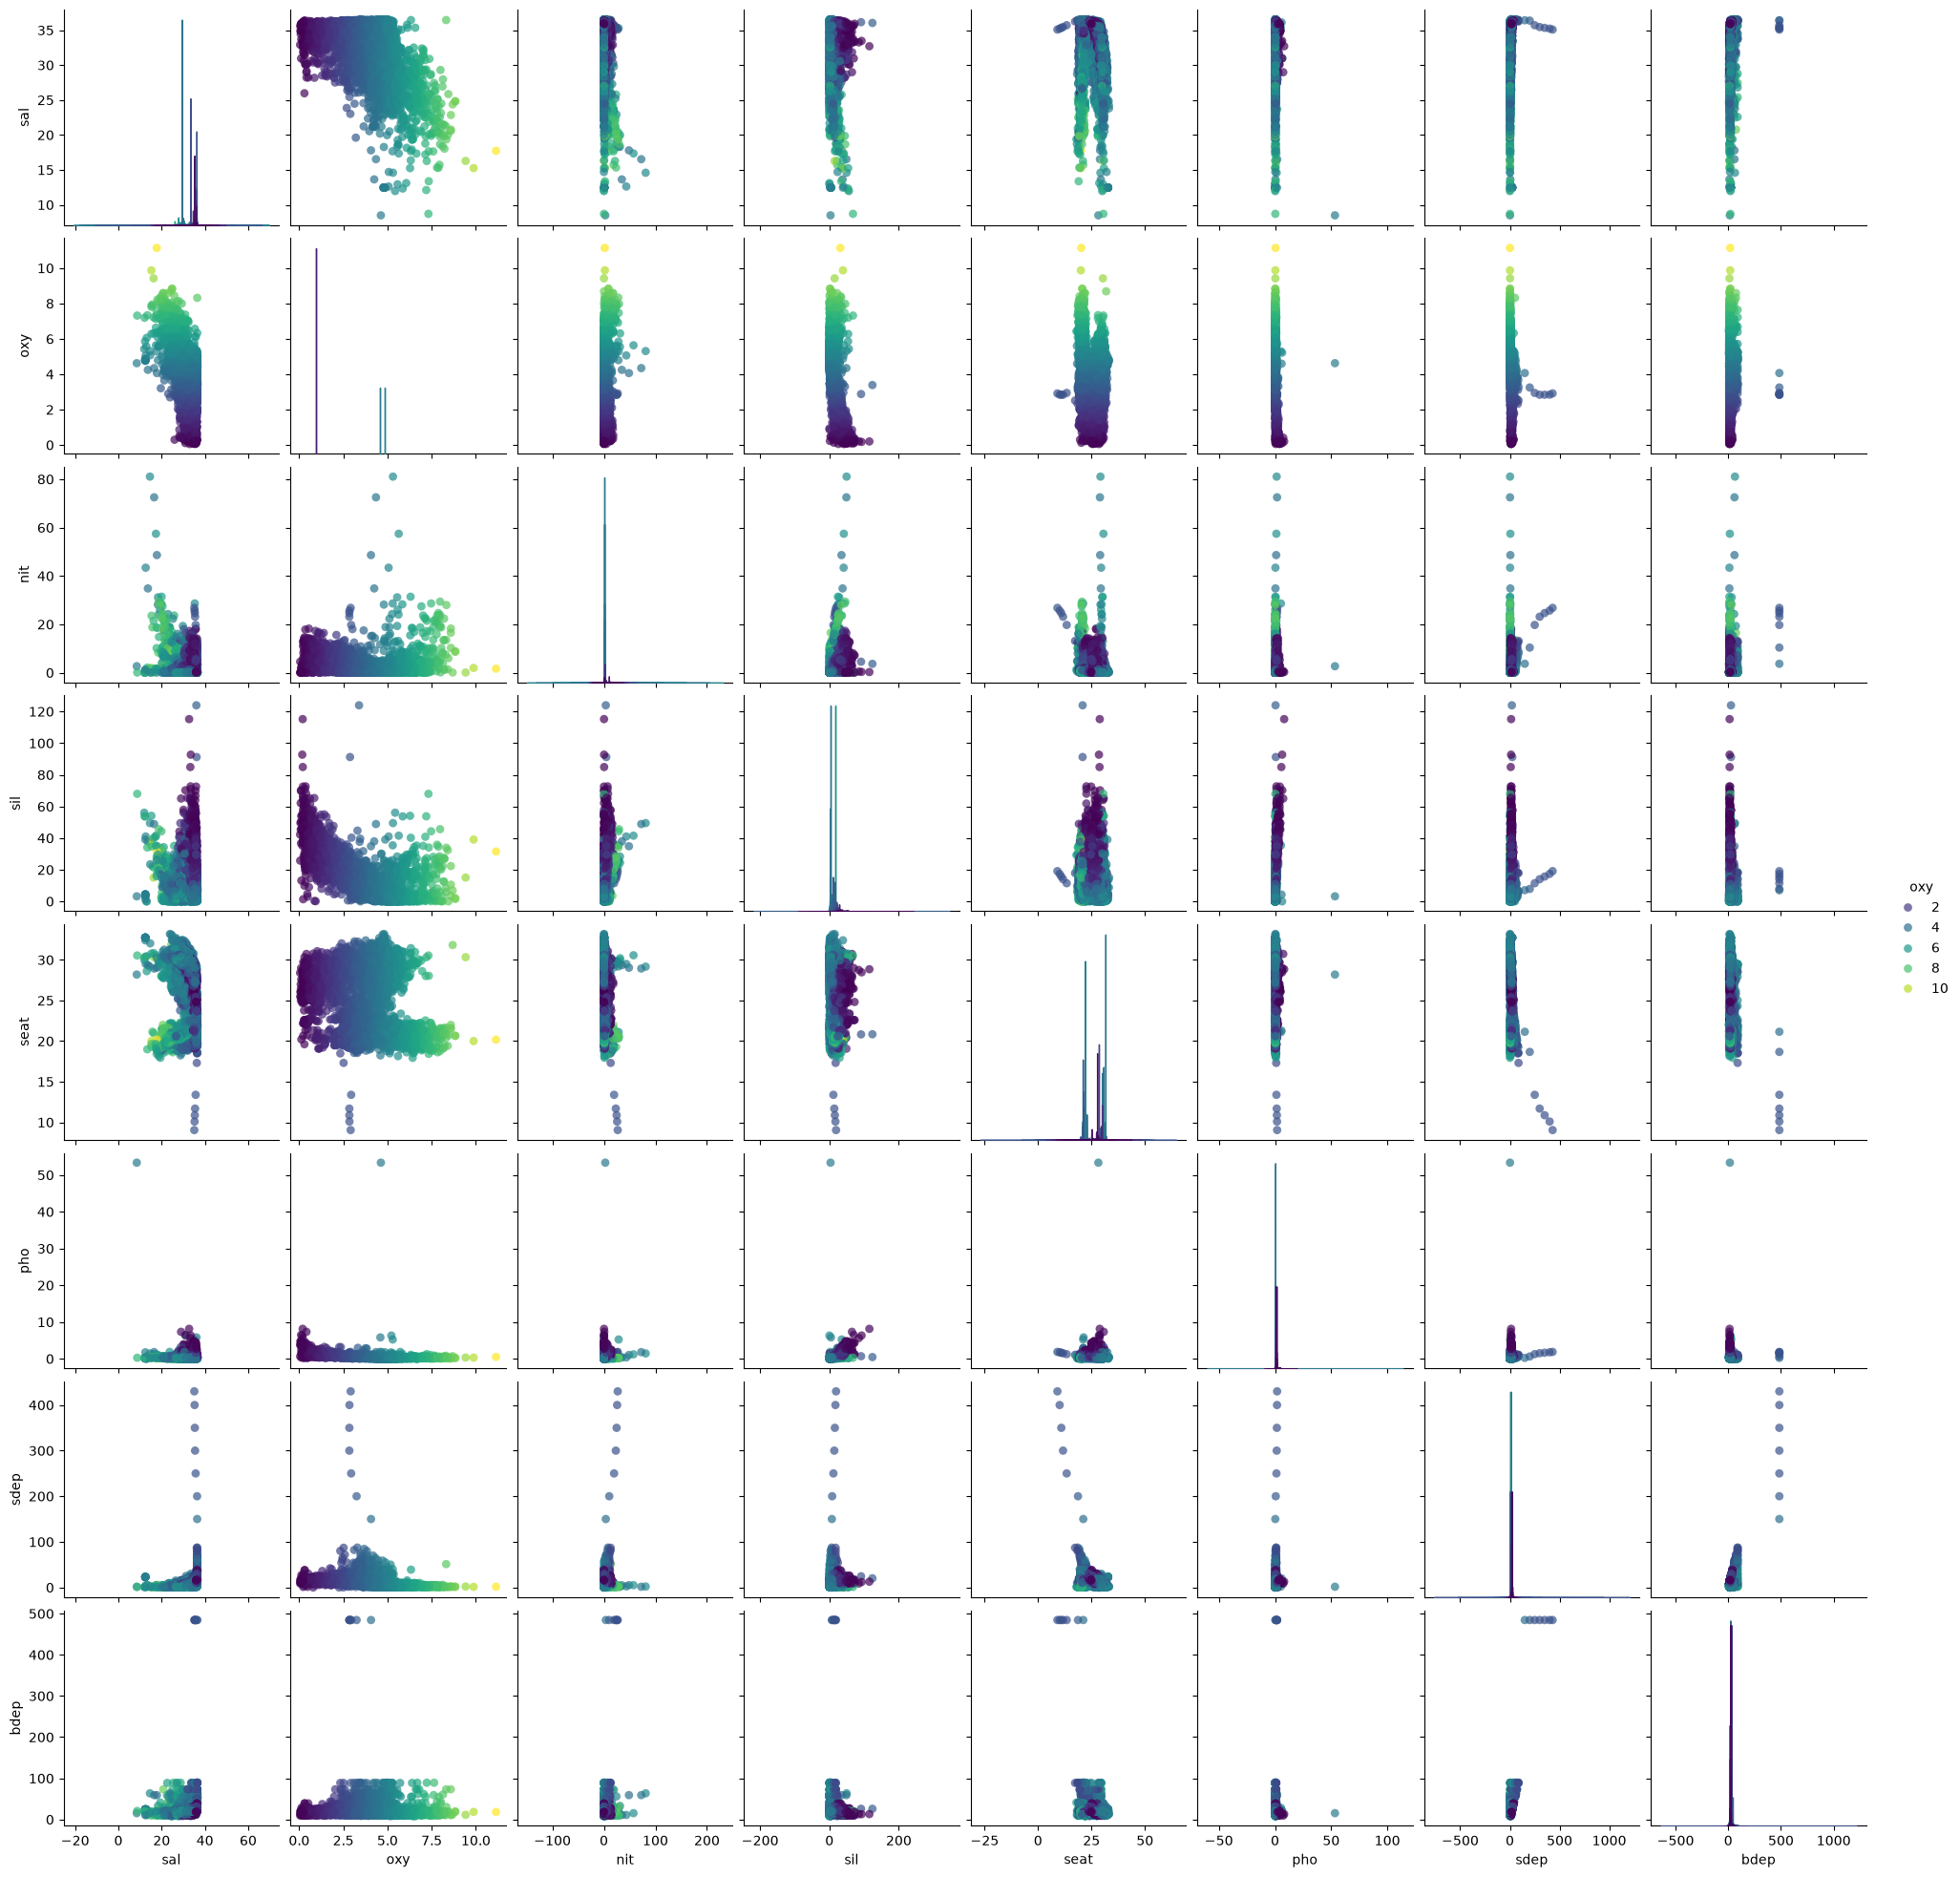

In [3]:
pca_data = lab10_observation[['sal','oxy','nit','sil','seat','pho', 'sdep', 'bdep']]

sns.pairplot(
    pca_data,
    vars=['sal','oxy','nit','sil','seat','pho', 'sdep', 'bdep'],
    hue='oxy',
    palette='viridis',
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 40, 'edgecolor': 'none'},
    diag_kws={'color': 'black'}
)

plt.show()

- Describe the trend between oxygen, salinity, temperature, and nutrients (silicate and nitrate).
- What do you think of the potential cause of low oxygen indicated by the data?
- Answer:\
Visually, there seems to be a negative correlation between salinity and oxygen, and between silicate and oxygen. The other factors (temperature, and nitrate) do not seem to be significantly correlated with oxygen levels. Because of this, high salinity and/or silicate concentrations should be looked at as potential causes of low oxygen.

In [4]:
#prepare your data for PCA
#select the variables you want to include in the PCA analysis
#what would you do for NA values?
pca_data= pca_data.dropna()

Bonus Point (5 point)
Plot the distribution of all the variables of your choice, use sns's kde.

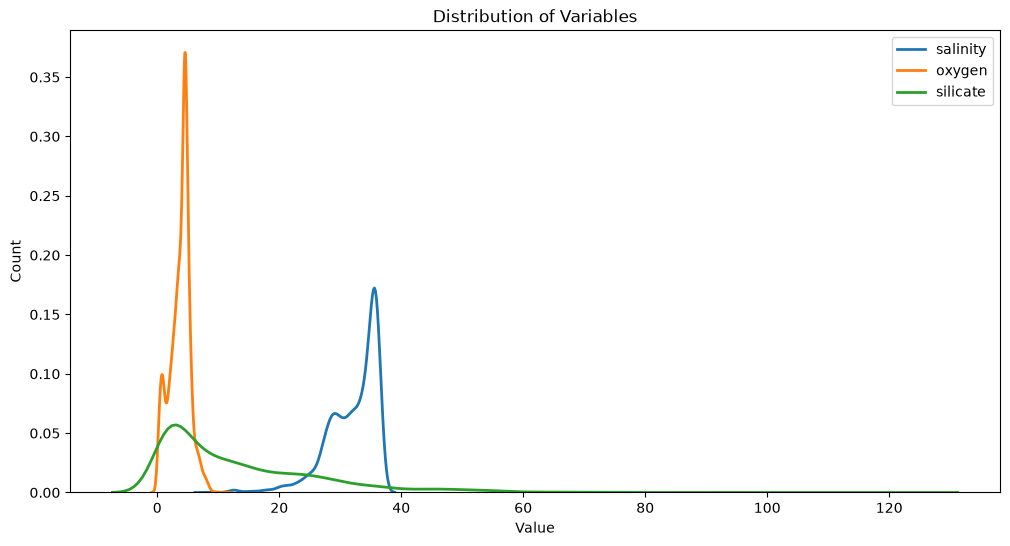

In [5]:
#bonus point code here
plt.figure(figsize=(12,6))
sns.kdeplot(pca_data['sal'], label="salinity", linewidth=2)
sns.kdeplot(pca_data['oxy'], label="oxygen", linewidth=2)
sns.kdeplot(pca_data['sil'], label="silicate", linewidth=2)
plt.title("Distribution of Variables")
plt.xlabel("Value")
plt.ylabel("Count")
plt.legend()
plt.show()

Why did you chose these variables? (explain them with the pairwise data and the trend)
- Answer:\
These are the variables that seemed the most correlated in the pairwise data (salinity/oxygen and silicate/oxygen)

In [6]:
#normalize the data for PCA analysis
scaler = StandardScaler()
pca_data_scaled = scaler.fit_transform(pca_data)
features = ['sal','oxy','nit','sil','seat','pho', 'sdep', 'bdep']
scaled_df = pd.DataFrame(pca_data_scaled, columns=features)
scaled_df.head()


,sal,oxy,nit,sil,seat,pho,sdep,bdep
0,-2.868185,0.489540,0.447879,-0.314000,-1.138505,-0.024388,-0.517237,-0.595943
1,-0.609675,0.291566,0.118822,-0.490549,-1.153440,-0.024388,-0.471400,-0.595943
2,-0.474743,-2.082908,-0.106195,-0.070958,-1.169775,-0.177925,-0.170185,-0.595943
3,-0.947803,1.335043,-0.183621,-0.888741,-1.073483,-0.116510,-0.654747,-0.160001
4,-0.722771,1.261945,1.556028,-0.127515,-1.088222,0.825188,-0.648199,-0.160001


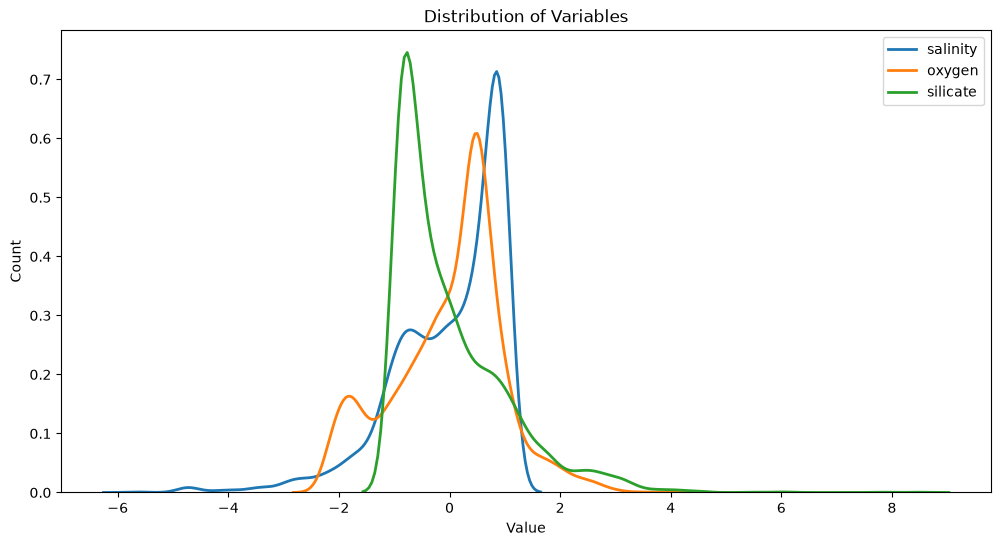

In [7]:
#plot distribution of your variables after normalization, use sns's kde
plt.figure(figsize=(12,6))
sns.kdeplot(scaled_df['sal'], label="salinity", linewidth=2)
sns.kdeplot(scaled_df['oxy'], label="oxygen", linewidth=2)
sns.kdeplot(scaled_df['sil'], label="silicate", linewidth=2)
plt.title("Distribution of Variables")
plt.xlabel("Value")
plt.ylabel("Count")
plt.legend()
plt.show()


Please answer the following questions:
- How many variable(s) show a "bimodal" distribution? And what are they?\
All three exhibit some level of bimodal distribution
- How many variable(s) show a "positively skewed unimodal" distribution? And what are they?\
Although all of the variables exhibit bimodal distribution, silicate seems positively skewed 
- How many variable(s) show a "negatively skewed unimodal" distribution? And what are they?\
Although all of the variables exhibit bimodal distribution, salinity and oxygen seem negatively skewed 
- How many variable(s) show a "uniform" distribution? And what are they?\
None of these variables exhibit uniform distribution

- What is the difference between the distribution of variable before and after normalization?
- (shape, spread, values)
- answer: Before normalization, the data is dificult to compare as it is centered about different values and some variable are more spread out or concentrated. After the data is normalized, the variables are all centered about 0 and are scaled to similar sizes
- Why do we normalize/scale the data for PCA here?\
This allows for an easier comparison of different aspects of each of the variables (amount of skew/bimodal distribution)

In [8]:
#create PCA model and save the results
#include the new data in PCA space, explained variance, and loadings
#and save them to new data frames


#these few lines of code run the PCA and save the results
pca = PCA() # initilize a PCA model, now it is empty, we did not specify number of componets, so it will keep all components by default
data_pcaed = pca.fit_transform(pca_data_scaled)  #the new data but in the PCA space
coeff = pca.components_           # (loadings)
latent = pca.explained_variance_    #
explained_var_ratio = pca.explained_variance_ratio_  # variance %

In [9]:
df_pca = pd.DataFrame(
    data_pcaed,
    columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8']
)

df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,1.538667,0.057060,2.247329,-0.328224,0.440258,-1.080791,0.968147,-0.925517
1,0.711747,0.118639,0.666530,-1.023053,0.470911,-0.034654,0.435230,-0.442621
2,-0.650835,-0.771489,-0.152593,-0.943000,-0.160890,-0.537404,1.162147,-1.663656
3,1.565793,0.831221,0.816746,-0.769715,0.811582,-0.117826,-0.008155,-0.222924
4,0.424593,0.260773,2.226206,-0.687129,0.728515,0.760571,-0.272429,0.058877


In [10]:
df_combined = pd.concat([df_pca, pca_data.reset_index(drop=True)], axis=1)
df_combined.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,sal,oxy,nit,sil,seat,pho,sdep,bdep
0,1.538667,0.057060,2.247329,-0.328224,0.440258,-1.080791,0.968147,-0.925517,20.1993,4.573,4.08,9.00,21.4497,0.49,4.2,10.2
1,0.711747,0.118639,0.666530,-1.023053,0.470911,-0.034654,0.435230,-0.442621,29.5492,4.248,2.72,6.69,21.3889,0.49,4.9,10.2
2,-0.650835,-0.771489,-0.152593,-0.943000,-0.160890,-0.537404,1.162147,-1.663656,30.1078,0.350,1.79,12.18,21.3224,0.34,9.5,10.2
3,1.565793,0.831221,0.816746,-0.769715,0.811582,-0.117826,-0.008155,-0.222924,28.1494,5.961,1.47,1.48,21.7144,0.40,2.1,19.8
4,0.424593,0.260773,2.226206,-0.687129,0.728515,0.760571,-0.272429,0.058877,29.0810,5.841,8.66,11.44,21.6544,1.32,2.2,19.8


### Part B Analyze PCA results

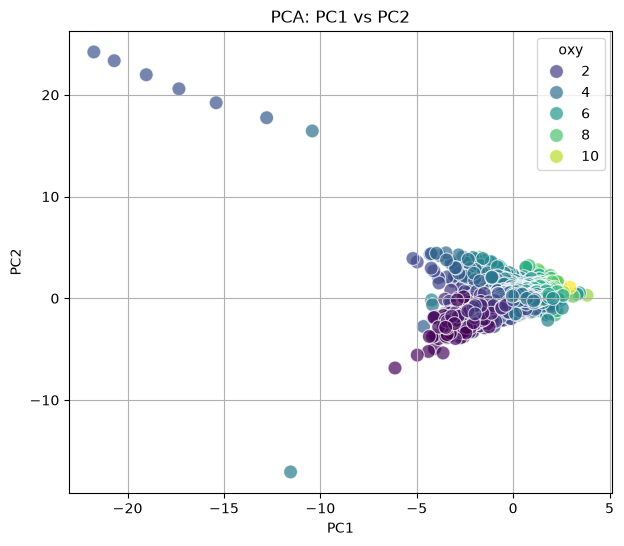

In [11]:
#plot the PCA results with two principal components that explain the most variance
#plot two plots, color them based on 2 variables (one oxygen, another of your choice)
plt.figure(figsize=(7,6))
sns.scatterplot(
    data = df_combined,
    x='PC1',
    y='PC2',
    hue='oxy',palette='viridis', #hue is for color coding and chose the right color map
    s=100,             #s is for marker size
    alpha = 0.7  #alpha is for marker transparency
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: PC1 vs PC2')
plt.grid(True)
plt.show()

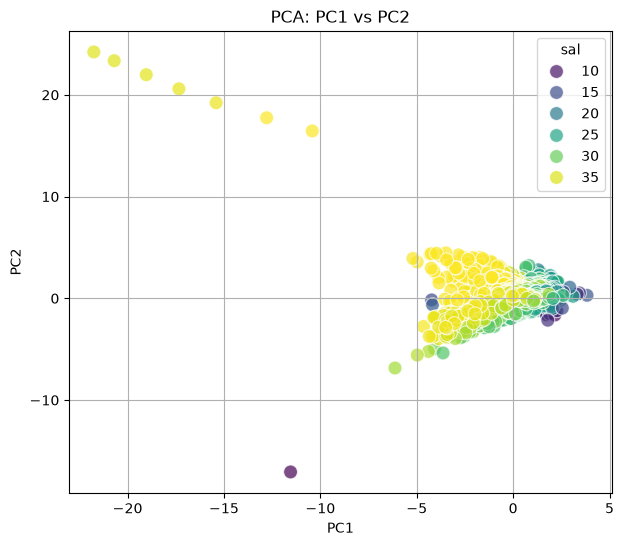

In [12]:
plt.figure(figsize=(7,6))
sns.scatterplot(
    data = df_combined,
    x='PC1',
    y='PC2',
    hue='sal',palette='viridis', #hue is for color coding and chose the right color map
    s=100,             #s is for marker size
    alpha = 0.7  #alpha is for marker transparency
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: PC1 vs PC2')
plt.grid(True)
plt.show()

In [13]:
#print out the co-efficients (loading) for each PC
loadings = pd.DataFrame(
    pca.components_,
    columns=features
)
#create a new column for PC names
#they are in order from 1 to 6
loadings['PC'] = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8']
print(loadings)

        sal       oxy       nit       sil      seat       pho      sdep  \
0 -0.384902  0.459811 -0.250466 -0.422978  0.194564 -0.273371 -0.453208   
1  0.021969  0.379335  0.024971 -0.402269 -0.305700 -0.310297  0.429594   
2 -0.558634  0.269487  0.686617  0.228258 -0.223007  0.195141 -0.062449   
3 -0.322015 -0.060489 -0.019077 -0.087811  0.776540  0.276772  0.224445   
4 -0.040640  0.221477 -0.399490 -0.169869 -0.325868  0.808910 -0.000558   
5  0.510151  0.051597  0.550396 -0.546338  0.181917  0.243866 -0.184482   
6 -0.300633 -0.322587  0.047380 -0.395506 -0.082227 -0.006998  0.583318   
7  0.288646  0.642355 -0.007988  0.340134  0.264386  0.021117  0.426008   

       bdep   PC  
0 -0.284247  PC1  
1  0.564705  PC2  
2  0.006957  PC3  
3  0.393166  PC4  
4  0.017967  PC5  
5 -0.095207  PC6  
6 -0.547556  PC7  
7 -0.369431  PC8  


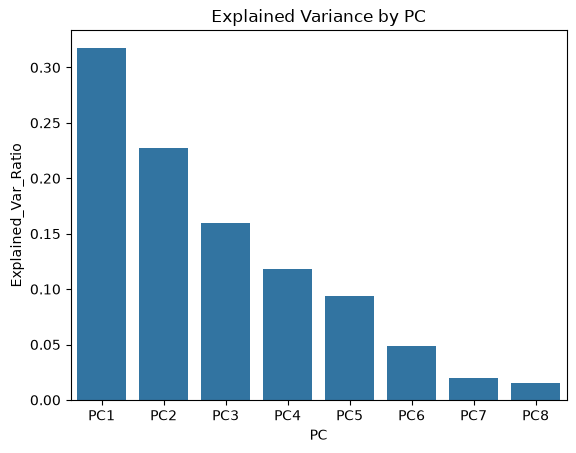

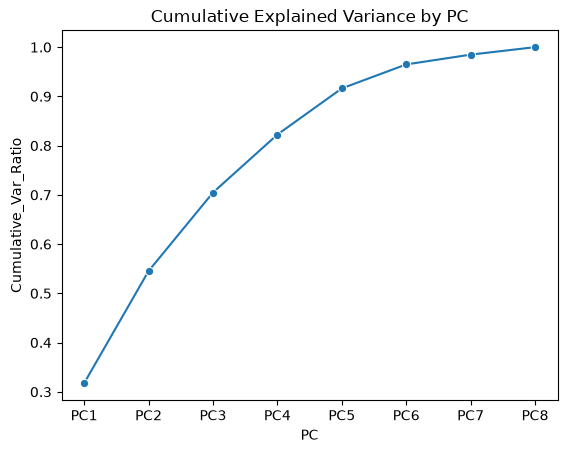

In [14]:
#plot cumulative variance explained by each PC
loadings['Explained_Var_Ratio'] = explained_var_ratio
sns.barplot(data = loadings, x='PC', y='Explained_Var_Ratio')
plt.title('Explained Variance by PC')
plt.show()

loadings['Cumulative_Var_Ratio'] = loadings['Explained_Var_Ratio'].cumsum()
sns.lineplot(data = loadings, x='PC', y='Cumulative_Var_Ratio', marker='o')
plt.title('Cumulative Explained Variance by PC')
plt.show()

Combining the plot/data from above
- What does PC1 and PC2 mean? (their relation to different variables, explain it with the coefficients)\
PC1 (principal component 1) is the 'axis' drawn through a dataset which accounts for the most varience, PC2 (principal component 2) is the 'axis' orthagonal to PC1
- What is the trend observed for the two variables you ploted with principlate components?\
As PC1 increases, PC2 'squeezes' to zero (the absolute value of PC2 gets smaller)
- Does it make sense considering the hypoxia process?\
Yes, with the color gradings we can see that the graph collapses to an area of low salinity and high oxygen, which remains consistant with previous observations
- What does PC3 mean?\
It is the last orthagonal (in 3 dimensions) 'axis' to PC1 and PC2, accounting for the least abount of variance ot of the three, but more than higher PCs

- Based on this plot, how many and which components would you chose for your PCA plot？\
At least 3, as the cumulative varience at PC3 gets just above 70%, though more could be used if more accuracy is desired.
- Do you think PC1 and PC2 are enough to explain the variance?\
No, while they probably give a good idea, they only cumulatively account for just above 50% of the varience and are not enought to explain the varience on their own.
- Will include PC3 help with explaining the varianc, the oxygen level, or any other trends? Why?\
Yes, it will help as it bumps up the cumulative varience explained to 70% giving a much better overall picture of the data than with just PC1 and PC2

In [15]:
#extract the data time and combine it with your PCA results
#convert the time format and extract month information
df_combined['date'] = lab10_observation['odate'].reset_index(drop=True)
df_combined['date'] = pd.to_datetime(df_combined['date'])
df_combined['month'] = df_combined['date'].dt.month
df_combined.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,sal,oxy,nit,sil,seat,pho,sdep,bdep,date,month
0,1.538667,0.057060,2.247329,-0.328224,0.440258,-1.080791,0.968147,-0.925517,20.1993,4.573,4.08,9.00,21.4497,0.49,4.2,10.2,2004-04-03 15:05:00.000002,4
1,0.711747,0.118639,0.666530,-1.023053,0.470911,-0.034654,0.435230,-0.442621,29.5492,4.248,2.72,6.69,21.3889,0.49,4.9,10.2,2004-04-03 15:05:00.000002,4
2,-0.650835,-0.771489,-0.152593,-0.943000,-0.160890,-0.537404,1.162147,-1.663656,30.1078,0.350,1.79,12.18,21.3224,0.34,9.5,10.2,2004-04-03 15:05:00.000002,4
3,1.565793,0.831221,0.816746,-0.769715,0.811582,-0.117826,-0.008155,-0.222924,28.1494,5.961,1.47,1.48,21.7144,0.40,2.1,19.8,2004-04-03 16:49:59.999999,4
4,0.424593,0.260773,2.226206,-0.687129,0.728515,0.760571,-0.272429,0.058877,29.0810,5.841,8.66,11.44,21.6544,1.32,2.2,19.8,2004-04-03 16:49:59.999999,4


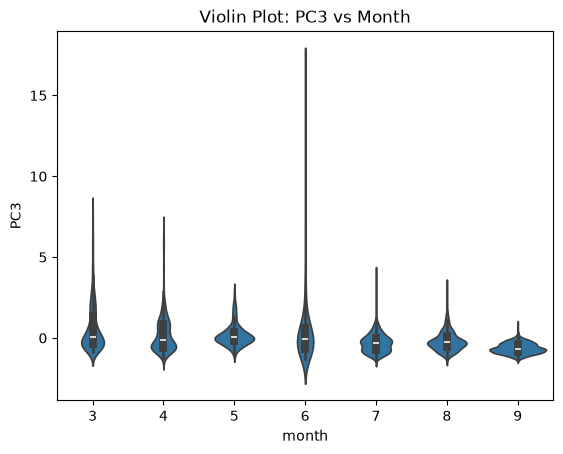

In [16]:
#plot violin plot of PC3 (hypoxia related) vs month to see if there is seasonal variability
sns.violinplot(
    data=df_combined,
    x='month',
    y='PC3'
    )
plt.xlabel('month')
plt.ylabel('PC3')
plt.title('Violin Plot: PC3 vs Month')
plt.show()

In [17]:
#perform ANOVA analysis to see if there is significant seasonal variability in PC3
#hint: you would need to extract the data for each month and pc3, 
#then run a tukey's test to see which months are significantly different from each other
#see the code from anova labs
#load related packages if they were not


#now lets do post hoc analysis
#we will use the function pairwise_tukeyhsd from statsmodels
tukey = pairwise_tukeyhsd(endog=df_combined['PC3'], #endogenous variables. i.e., the data values, the measurements you try to explain/compare
                          groups=df_combined['month'], 
                          alpha=0.05) #significance level
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     3      4  -0.3737    0.0 -0.5573 -0.1902   True
     3      5  -0.4701    0.0 -0.6604 -0.2797   True
     3      6  -0.1012 0.8272 -0.3221  0.1196  False
     3      7  -0.9259    0.0 -1.0759  -0.776   True
     3      8  -0.8178    0.0 -0.9812 -0.6545   True
     3      9  -1.2749    0.0  -1.451 -1.0987   True
     4      5  -0.0963 0.8071 -0.3006   0.108  False
     4      6   0.2725 0.0101  0.0396  0.5055   True
     4      7  -0.5522    0.0 -0.7194 -0.3849   True
     4      8  -0.4441    0.0 -0.6235 -0.2647   True
     4      9  -0.9011    0.0 -1.0923 -0.7099   True
     5      6   0.3688 0.0001  0.1305  0.6072   True
     5      7  -0.4559    0.0 -0.6305 -0.2812   True
     5      8  -0.3478    0.0 -0.5341 -0.1615   True
     5      9  -0.8048    0.0 -1.0025 -0.6071   True
     6      7  -0.8247    0.0 -1.0322 -0.6172 

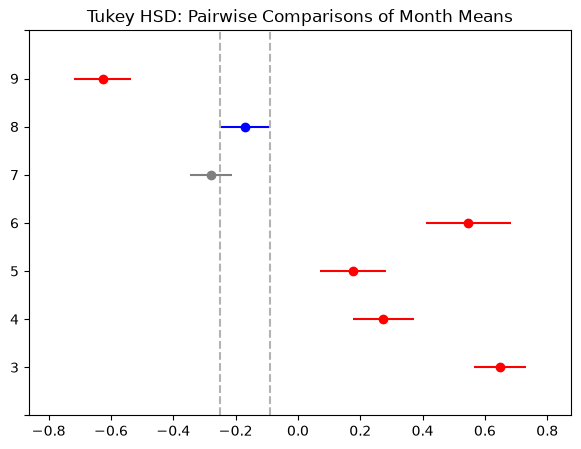

In [18]:

#produce a tukey's test plot comparing the months
tukey.plot_simultaneous(comparison_name=8, figsize=(7,5))
plt.title("Tukey HSD: Pairwise Comparisons of Month Means")
plt.show()

- How many months are significantly different than August?\
All measured months but July are significantly different than August 
- What does this mean? Explain in relation to what PC3 mean and how is that related to hypoxia process.\
This means that time is likely a significant factor (in other words there is likely significant seasonal variability in hypoxia) that is, at least to some extent, accounted for in PC3 that is not be accounted for in PC1 or PC2 as they are perpendicular to it and do not overlap in varience. Further support for including PC3 to better describe the dataset.